Workflow

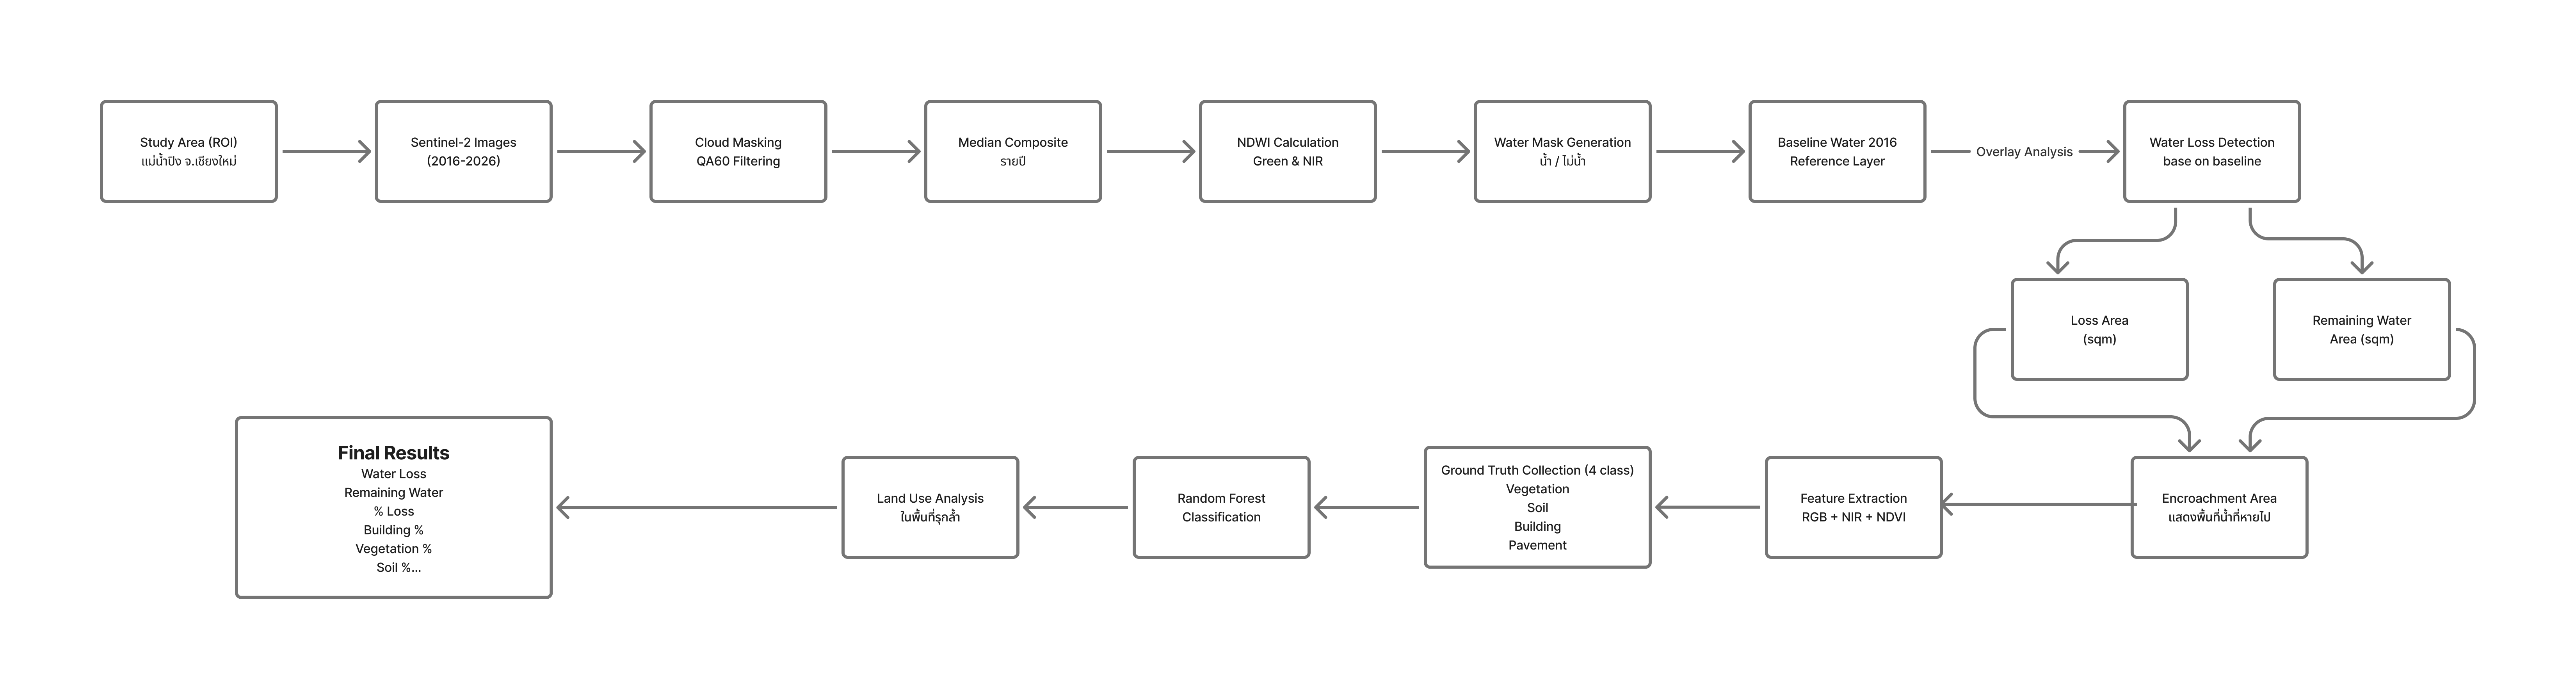

In [1]:
import ee
import geemap

ee.Authenticate()
project_name = ''
ee.Initialize(project=project_name)

## **1. กำหนดพื้นที่เป้าหมาย (แม่น้ำปิง เมืองเชียงใหม่)**




In [2]:
import geemap
import ee

# Define aoi_coords_Ping globally
aoi_coords_Ping = [
[98.99903317431634,18.800966130104587],
[98.99748822192376,18.795603472648168],
[99.00092144946282,18.789428079720047],
[99.00195141772454,18.782927421464446],
[98.99834652880853,18.775776407657514],
[99.00126477221673,18.76586200024984],
[98.99422665576165,18.762448708705392],
[98.9998914812011,18.75887280538074],
[99.00710125903313,18.76163601006083],
[99.00950451831048,18.77870185907682],
[99.00452633837884,18.792678314756998],
[99.00675793627923,18.809903512794353],
[99.00092144946282,18.81039099274085],
[98.99903317431634,18.800966130104587]
]

# Define roi globally
roi = ee.Geometry.Polygon([aoi_coords_Ping])

def create_roi_map(roi_geometry, layer_name="AOI"):
    """
    ฟังก์ชันสำหรับสร้างแผนที่และวาดกรอบพื้นที่ศึกษาจาก Earth Engine Geometry

    Parameters:
    - roi_geometry: ขอบเขตพื้นที่ศึกษา (ee.Geometry)
    - layer_name: ชื่อของเลเยอร์ที่ต้องการแสดงบนแผนที่
    """
    # 2. สร้างอ็อบเจกต์แผนที่
    m = geemap.Map()

    # 3. ซูมเข้ากึ่งกลางพื้นที่
    m.centerObject(roi_geometry, zoom=13)

    # 4. แสดงผลกรอบพื้นที่ศึกษา
    m.add_layer(roi_geometry, {'color': 'red', 'fillColor': '#00000000'}, layer_name)

    return m

Map_AOI = create_roi_map(roi, "Ping River Riverside") # Pass the global roi to the function
Map_AOI

Map(center=[18.782625383224545, 99.0031932693862], controls=(WidgetControl(options=['position', 'transparent_b…

## **2. ดึงข้อมูลภาพถ่ายดาวเทียม Sentinel-2**

In [3]:
def mask_s2_clouds(image):
    qa = image.select('QA60')
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(qa.bitwiseAnd(cirrus_bit_mask).eq(0))
    cleaned = image.updateMask(mask).divide(10000)
    # รีเนมแบนด์ส่งออกเป็นชื่อสากล
    return cleaned.select(['B3', 'B8', 'B4', 'B2'], ['Green', 'NIR', 'Red', 'Blue'])

## **3. ดึงภาพปี 2016 (Baseline) - โครงสร้างเวลา 4 เดือน (พ.ย. - ก.พ.)**

In [4]:
import datetime
print("กำลังดึงและตรวจสอบข้อมูล Baseline ปี 2016...")

baseline_collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                    .filterBounds(roi)
                    .filterDate('2016-11-01', '2017-03-01')
                    .filter(ee.Filter.calendarRange(11, 12, 'month').Or(ee.Filter.calendarRange(1, 2, 'month')))
                    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
                    .map(mask_s2_clouds))

collection_size = baseline_collection.size().getInfo()

if collection_size == 0:
    raise RuntimeError("พังตั้งแต่เริ่ม: ปี Baseline 2016 ไม่มีภาพดาวเทียมที่ผ่านเงื่อนไขเลย")

print(f"ตรวจพบภาพดาวเทียมผ่านเกณฑ์ทั้งหมด: {collection_size} ภาพ")
print("ลำดับเวลา (Timestamp) ของภาพที่ถูกดีกเข้ามาใช้งาน:")

# สกัดลิสต์เวลาฝั่ง Server ออกมารวมกันทีเดียว แล้วแปลงเป็นวันที่ใน Python
timestamps = baseline_collection.aggregate_array('system:time_start').getInfo()

for i, ts in enumerate(timestamps):
    date_obj = datetime.datetime.fromtimestamp(ts / 1000.0, datetime.timezone.utc)
    date_str = date_obj.strftime('%Y-%m-%d')
    print(f"   [{i + 1}] ภาพถ่ายวันที่: {date_str}")

# สร้างภาพค่ามัธยฐาน (Median Composite)
dataset_baseline = baseline_collection.median().clip(roi)

baseline_bands = dataset_baseline.bandNames().getInfo()
if 'Green' not in baseline_bands:
    raise RuntimeError(f"ภาพ Baseline 2016 ไม่มีแบนด์ 'Green' อยู่จริง (แบนด์ที่มีคือ: {baseline_bands})")

# คำนวณหน้ากากผิวน้ำตั้งต้น
water_baseline_raw = dataset_baseline.normalizedDifference(['Green', 'NIR']).gt(0.0)

# เปลี่ยนจาก eightyConnected เป็น eightConnected ให้ตรงตาม API ของ Earth Engine
connected_features = water_baseline_raw.connectedPixelCount(maxSize=100, eightConnected=True)

# คัดกรอง: เก็บเฉพาะกลุ่มพิกเซลน้ำที่เกาะกลุ่มกันมากกว่าหรือเท่ากับ 50 พิกเซลขึ้นไป (ตัดสระน้ำเล็กๆ ออก)
water_baseline = water_baseline_raw.updateMask(connected_features.gte(50))

print("\nข้อมูล Baseline ปี 2016 (พ.ศ. 2559) ประมวลผลและพร้อมใช้งาน")

กำลังดึงและตรวจสอบข้อมูล Baseline ปี 2016...
ตรวจพบภาพดาวเทียมผ่านเกณฑ์ทั้งหมด: 3 ภาพ
ลำดับเวลา (Timestamp) ของภาพที่ถูกดีกเข้ามาใช้งาน:

ข้อมูล Baseline ปี 2016 (พ.ศ. 2559) ประมวลผลและพร้อมใช้งาน


In [5]:
import geemap

def visualize_water_mask(dataset, water_mask, roi, layer_name="Dataset"):
    """
    ฟังก์ชันสำหรับแสดงผลภาพถ่ายดาวเทียมและหน้ากากผิวน้ำอัตโนมัติ

    Parameters:
    - dataset: image collection หรือ image ที่ต้องการแสดง
    - water_mask: mask ของผิวน้ำที่สกัดได้
    - roi: ขอบเขตพื้นที่ศึกษา (ee.Geometry)
    - layer_name: ชื่อส่วนนำหน้าสำหรับ Layer (String)
    """
    # สร้างอ็อบเจกต์แผนที่
    m = geemap.Map()
    m.centerObject(roi, zoom=13)

    # 1. แสดงภาพถ่ายดาวเทียม (True Color)
    rgb_params = {
        'bands': ['Red', 'Green', 'Blue'],
        'min': 0.0,
        'max': 0.3
    }
    m.add_layer(dataset, rgb_params, f'{layer_name} (True Color)')

    # 2. แสดงหน้ากากผิวน้ำ
    # ใช้สีน้ำเงินสว่างพร้อมความโปร่งใสในส่วนที่ไม่ใช่น้ำ
    water_viz_params = {
        'min': 0,
        'max': 1,
        'palette': ['#00000000', '#0066FF']
    }
    m.add_layer(water_mask, water_viz_params, f'{layer_name} (Water Mask)')

    # 3. วาดเส้นกรอบพื้นที่ศึกษา (ROI)
    m.add_layer(roi, {'color': 'red', 'fillColor': '#00000000'}, 'Study Area (ROI)')

    return m

m_output = visualize_water_mask(dataset_baseline, water_baseline, roi, "Baseline 2016")
m_output

Map(center=[18.782625383224545, 99.0031932693862], controls=(WidgetControl(options=['position', 'transparent_b…

## **4. ลูปดึงข้อมูลรายปีทุกๆ ปี (ตั้งแต่ 2017 จนถึงปีล่าสุด 2026) โดยกรองเฉพาะ 4 เดือน (11, 12, 1, 2) เหมือนกันทั้งหมด**

In [6]:
print("\nกำลังเริ่มดึงข้อมูลรายปี...")
yearly_datasets = {}
yearly_water = {}

for year in range(2017, 2027):
    start_date = f"{year-1}-11-01"
    end_date = f"{year}-03-01"
    thai_year = year + 543

    img_collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                     .filterBounds(roi)
                     .filterDate(start_date, end_date)
                     .filter(ee.Filter.calendarRange(11, 12, 'month').Or(ee.Filter.calendarRange(1, 2, 'month')))
                     .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)) # ใช้ 20% เท่ากันเพื่อความชัวร์
                     .map(mask_s2_clouds))

    if img_collection.size().getInfo() == 0:
        print(f"พ.ศ. {thai_year}: ไม่มีภาพผ่านเงื่อนไข (ข้ามปีนี้)")
        continue

    yearly_img = img_collection.median().clip(roi)
    band_names = yearly_img.bandNames().getInfo()

    # ดักจับถ้าเกิดกรณีแบนด์ว่างในลูปรายปี
    if 'Green' not in band_names:
        print(f"พ.ศ. {thai_year}: ตรวจพบภาพว่างเปล่า ไม่มีแบนด์ 'Green' (ข้ามปีนี้)")
        continue

    water_img = yearly_img.normalizedDifference(['Green', 'NIR']).gt(0.0)

    yearly_datasets[thai_year] = yearly_img
    yearly_water[thai_year] = water_img
    print(f"พ.ศ. {thai_year}: ดึงข้อมูลสำเร็จ")

print("\n--- คลังข้อมูลรายปีเซ็ตอัปเสร็จสิ้น ---")


กำลังเริ่มดึงข้อมูลรายปี...
พ.ศ. 2560: ดึงข้อมูลสำเร็จ
พ.ศ. 2561: ดึงข้อมูลสำเร็จ
พ.ศ. 2562: ดึงข้อมูลสำเร็จ
พ.ศ. 2563: ดึงข้อมูลสำเร็จ
พ.ศ. 2564: ดึงข้อมูลสำเร็จ
พ.ศ. 2565: ดึงข้อมูลสำเร็จ
พ.ศ. 2566: ดึงข้อมูลสำเร็จ
พ.ศ. 2567: ดึงข้อมูลสำเร็จ
พ.ศ. 2568: ดึงข้อมูลสำเร็จ
พ.ศ. 2569: ดึงข้อมูลสำเร็จ

--- คลังข้อมูลรายปีเซ็ตอัปเสร็จสิ้น ---


## **5. ฟังก์ชันคำนวณพื้นที่พิกเซล (ตารางเมตร)**

In [7]:
def calculate_section_area(mask_image, section_geometry):
    area_img = mask_image.multiply(ee.Image.pixelArea())
    stats = area_img.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=section_geometry,
        scale=10, # ความละเอียดพิกเซล Sentinel-2
        maxPixels=1e9
    )
    # คืนค่ากลับมาเป็นตัวเลข ถ้าพิกเซลว่างให้ส่งกลับเป็น 0
    return ee.Number(stats.get(stats.keys().get(0), 0)).round()

## **6. วนลูปสกัด "พื้นที่รุกล้ำ/ตลิ่งงอก" แยกรายช่วง และรายปี**

In [8]:
import pandas as pd

# 1. คำนวณหาพื้นที่น้ำฐานรวมทั้งหมดปี 2559 (Baseline) ภายในขอบเขต roi
total_base_water_area = calculate_section_area(water_baseline, roi).getInfo()

print("สรุปผลการวิเคราะห์พื้นที่รุกล้ำและผิวน้ำที่คงเหลือ (Total & Remaining Analysis)")
print(f"พื้นที่น้ำฐานปี พ.ศ. 2559 (Baseline Total): {total_base_water_area:,.0f} ตร.ม.")

overall_records = []

# 2. วนลูปคำนวณข้อมูลรายปี
for th_year in sorted(yearly_water.keys()):
    water_this_year = yearly_water[th_year]

    # ตรรกะคัดแยกชิ้นเนื้อ Loss (เคยเป็นน้ำในปี 59 แต่ปัจจุบันในแต่ละปีไม่ใช่แล้ว)
    loss_mask = water_baseline.And(water_this_year.Not())

    # คำนวณพื้นที่รุกล้ำรวม (Loss)
    total_loss_area = calculate_section_area(loss_mask, roi).getInfo()

    # หาพื้นที่ผิวน้ำที่เหลืออยู่จริงในแม่น้ำ
    remaining_water_area = total_base_water_area - total_loss_area

    # คำนวณเปอร์เซ็นต์การหายไปสะสมเมื่อเทียบกับน้ำฐานรวม
    pct_loss_overall = (total_loss_area / total_base_water_area * 100) if total_base_water_area > 0 else 0

    # บันทึกข้อมูลลงรายบันทึกภาพรวม
    overall_records.append({
        "Year_TH": th_year,
        "Total_Base_Water_Sqm": total_base_water_area,
        "Total_Loss_Area_Sqm": total_loss_area,
        "Remaining_Water_Sqm": remaining_water_area,
        "Percentage_Loss": pct_loss_overall
    })

    # ปริ้นต์สรุปให้เห็นทั้งสองฝั่ง
    print(f"พ.ศ. {th_year} -> รุกล้ำสะสม: {total_loss_area:,.0f} ตร.ม. ({pct_loss_overall:.2f}%) "
          f"|  คงเหลือผิวน้ำจริง: {remaining_water_area:,.0f} ตร.ม.")

# แปลงผลลัพธ์เป็น DataFrame
df_overall_analysis = pd.DataFrame(overall_records)


สรุปผลการวิเคราะห์พื้นที่รุกล้ำและผิวน้ำที่คงเหลือ (Total & Remaining Analysis)
พื้นที่น้ำฐานปี พ.ศ. 2559 (Baseline Total): 330,353 ตร.ม.
พ.ศ. 2560 -> รุกล้ำสะสม: 0 ตร.ม. (0.00%) |  คงเหลือผิวน้ำจริง: 330,353 ตร.ม.
พ.ศ. 2561 -> รุกล้ำสะสม: 16,104 ตร.ม. (4.87%) |  คงเหลือผิวน้ำจริง: 314,249 ตร.ม.
พ.ศ. 2562 -> รุกล้ำสะสม: 15,915 ตร.ม. (4.82%) |  คงเหลือผิวน้ำจริง: 314,438 ตร.ม.
พ.ศ. 2563 -> รุกล้ำสะสม: 38,329 ตร.ม. (11.60%) |  คงเหลือผิวน้ำจริง: 292,024 ตร.ม.
พ.ศ. 2564 -> รุกล้ำสะสม: 40,905 ตร.ม. (12.38%) |  คงเหลือผิวน้ำจริง: 289,448 ตร.ม.
พ.ศ. 2565 -> รุกล้ำสะสม: 21,095 ตร.ม. (6.39%) |  คงเหลือผิวน้ำจริง: 309,258 ตร.ม.
พ.ศ. 2566 -> รุกล้ำสะสม: 6,969 ตร.ม. (2.11%) |  คงเหลือผิวน้ำจริง: 323,384 ตร.ม.
พ.ศ. 2567 -> รุกล้ำสะสม: 16,198 ตร.ม. (4.90%) |  คงเหลือผิวน้ำจริง: 314,155 ตร.ม.
พ.ศ. 2568 -> รุกล้ำสะสม: 9,135 ตร.ม. (2.77%) |  คงเหลือผิวน้ำจริง: 321,218 ตร.ม.
พ.ศ. 2569 -> รุกล้ำสะสม: 9,229 ตร.ม. (2.79%) |  คงเหลือผิวน้ำจริง: 321,124 ตร.ม.


In [9]:
import geemap

def get_grayscale_image(img):
    """แปลงภาพสีจริงให้เป็นโทนเทาขาวสว่าง (Light Grayscale) เพื่อทำหน้าที่เป็นพื้นหลัง"""
    gray = img.select('Red').multiply(0.299) \
              .add(img.select('Green').multiply(0.587)) \
              .add(img.select('Blue').multiply(0.114))

    # ปรับ Gain (3.8) และ Offset (0.1) เพื่อดึงให้ฉากหลังโดยรอบกลายเป็นสีเทาสว่าง/เทาขาว
    # ช่วยให้จุดไฮไลท์สีแดงเด้งลอยเด่นขึ้นมาจากแผนที่อย่างชัดเจน
    gray_bright = gray.multiply(3.8).add(0.1)
    return ee.Image.cat([gray_bright, gray_bright, gray_bright])

def visualize_overall_encroachment(input_year_th):
    """เรนเดอร์แผนที่แสดงไฮไลท์พื้นที่รุกล้ำสีแดงบนพื้นหลังขาวดำแบบภาพรวม Clean Look"""
    print(f"กำลังสร้างแผนที่ High-Contrast แสดงจุดรุกล้ำ พ.ศ. {input_year_th}...")

    # 1. ตรวจสอบข้อมูลนำเข้า
    if input_year_th not in yearly_water:
        raise ValueError(f"ไม่มีข้อมูลของปี พ.ศ. {input_year_th} ในคลังข้อมูล")

    # 2. ดึงชุดข้อมูลตามปีที่เลือก
    target_img = yearly_datasets[input_year_th]
    water_this_year = yearly_water[input_year_th]

    # ตรรกะคัดแยกชิ้นเนื้อรุกล้ำ (เคยเป็นน้ำในปี 59 แต่ปัจจุบันโดนตลิ่ง/สิ่งปลูกสร้างขยับแทนที่)
    loss_mask = water_baseline.And(water_this_year.Not())

    # 3. เรียกหน้าต่างแผนที่หลักและโฟกัสภาพรวม ROI
    m_overall = geemap.Map()
    m_overall.centerObject(roi, zoom=14)  # Zoom 14 เพื่อเห็นแนวคุ้งน้ำปิงยาวต่อเนื่อง

    # 4. Layer ที่ 1: ภาพดาวเทียมพื้นหลังเทาขาว (Clip เฉพาะในกรอบพื้นที่ศึกษา)
    grayscale_bg = get_grayscale_image(target_img).clip(roi)
    # ตั้งค่า max เป็น 0.85 เพื่อคุมไม่ให้พื้นหลังจ้าจนแสบตาเกินไป
    m_overall.add_layer(grayscale_bg, {'min': 0.1, 'max': 0.85}, f'1. ภาพดาวเทียมพื้นหลัง พ.ศ. {input_year_th}')

    loss_viz_params = {
        'min': 1,
        'max': 1,
        'palette': ['#FF0000']  # Pure Neon Red
    }
    m_overall.add_layer(loss_mask.updateMask(loss_mask).clip(roi), loss_viz_params, f'2. จุดที่ตลิ่งขยับรุกล้ำจากปี 2559 (สีแดง)')
    return m_overall

print("อัปเดตฟังก์ชันแผนที่ภาพรวมฉบับ Clean Look & High-Contrast เรียบร้อย")

อัปเดตฟังก์ชันแผนที่ภาพรวมฉบับ Clean Look & High-Contrast เรียบร้อย


In [10]:
# สั่งรันฟังก์ชันระบบภาพรวม และแสดงแผนที่ผลลัพธ์ออกสู่หน้าจอ
SELECT_YEAR_TH = 2569
m_overall_final = visualize_overall_encroachment(SELECT_YEAR_TH)
m_overall_final

กำลังสร้างแผนที่ High-Contrast แสดงจุดรุกล้ำ พ.ศ. 2569...


Map(center=[18.782625383224545, 99.0031932693862], controls=(WidgetControl(options=['position', 'transparent_b…

## **7. สร้างโมเดล Machine Lerning**

 7.1. สร้างชุดข้อมูลตัวอย่าง (Training Data) เพื่อสอน AI สำหรับจำแนกประเภทที่ดิน

In [11]:
print("================================================================")
print("ขั้นตอนที่ 1: เตรียมภาพดาวเทียมปีล่าสุดและคำนวณดัชนีชี้วัด (NDVI & NDBI)")
print("================================================================")

# 1. ดึงภาพดาวเทียมปีล่าสุด (พ.ศ. 2569) ออกมาจากคอลเลกชันของคุณ
latest_th_year = max(yearly_water.keys())
image_latest = yearly_datasets[latest_th_year]

# 2. คำนวณดัชนี NDVI (แยกพืช) และ NDBI (แยกสิ่งปลูกสร้าง)
ndvi_latest = image_latest.normalizedDifference(['NIR', 'Red']).rename('NDVI')

band_names = image_latest.bandNames().getInfo()
if 'B11' in band_names:
    ndbi_latest = image_latest.normalizedDifference(['B11', 'NIR']).rename('NDBI')
else:
    ndbi_latest = image_latest.normalizedDifference(['Red', 'Blue']).rename('NDBI')

# 3. มัดรวมแบนด์ทั้งหมดเข้าด้วยกันเพื่อสร้าง ai_input_image ให้โมเดลรู้จัก
ai_input_image = image_latest.select(['Red', 'Green', 'Blue', 'NIR']).addBands([ndvi_latest, ndbi_latest])

print("สร้างตัวแปร ai_input_image พร้อมแบนด์ดัชนีชี้วัดเรียบร้อยแล้ว!")
print("----------------------------------------------------------------")
print("ขั้นตอนที่ 2: ดึงแผนที่ Dynamic World และ ESA เพื่อปั๊มจุด 4 คลาส (รวมดินและถนน)")
print("----------------------------------------------------------------")

# 1. เรียกดูแผนที่ Dynamic World บริเวณ ROI สำหรับคลาสพืชพรรณ ตึก และถนน
dw = ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1') \
       .filterBounds(roi) \
       .filterDate('2023-01-01', '2023-12-31') \
       .select('label') \
       .mosaic() \
       .clip(roi)

# 2. แยกคลาส Built area ของ Dynamic World ออกเป็น ตึก (2) และ ถนน (3)
built_mask = dw.eq(6)
building_layer = built_mask.And(ndbi_latest.gte(0.1))
pavement_layer = built_mask.And(ndbi_latest.lt(0.1))

# 3. สร้างหน้ากาก 3 คลาสหลักตั้งต้น (0: Vegetation, 2: Building, 3: Pavement)
custom_map = ee.Image(0).where(dw.eq(1).Or(dw.eq(2)), 0) \
                        .where(building_layer, 2) \
                        .where(pavement_layer, 3) \
                        .rename('my_landcover')

samples_3_classes = custom_map.stratifiedSample(
    numPoints=2500,
    classBand='my_landcover',
    region=roi,
    scale=10,
    geometries=True
)

# 4a. Soil จาก ESA WorldCover (2020) + กรองด้วย NDBI ปีล่าสุด กันจุดที่กลายเป็นตึก/พื้นปูนไปแล้ว
esa_soil = ee.ImageCollection('ESA/WorldCover/v100').first().select('Map')
soil_mask_verified = esa_soil.eq(60).And(ndbi_latest.lt(0.1))

samples_soil_esa = esa_soil.updateMask(soil_mask_verified).stratifiedSample(
    numPoints=1500,
    classBand='Map',
    region=roi,
    scale=10,
    geometries=True
).map(lambda f: f.set('my_landcover', 1))

# 4b. Soil จาก Dynamic World bare ground (label=7) ปี 2023 เดียวกับ Building/Pavement
soil_layer_dw = dw.eq(7)

samples_soil_dw = soil_layer_dw.selfMask().stratifiedSample(
    numPoints=1500,
    classBand='label',
    region=roi,
    scale=10,
    geometries=True
).map(lambda f: f.set('my_landcover', 1))

# 4c. รวม Soil จากทั้ง 2 แหล่งเข้าด้วยกัน เพื่อเพิ่มจำนวนจุดให้มากที่สุดเท่าที่พื้นที่มีจริง
samples_soil = samples_soil_esa.merge(samples_soil_dw)

print("จำนวนจุด Soil จาก ESA (กรอง NDBI):", samples_soil_esa.size().getInfo())
print("จำนวนจุด Soil จาก Dynamic World bare:", samples_soil_dw.size().getInfo())
print("จำนวนจุด Soil รวมทั้งหมด:", samples_soil.size().getInfo())

# 5. รวมจุดฝึกสอนจากทั้ง 2 แหล่งเข้าด้วยกันเป็น 4 คลาสสมบูรณ์
training_samples_auto = samples_3_classes.merge(samples_soil)

# 6. สกัดค่าแสงสะท้อนส่งต่อให้ฝั่ง Python
trained_samples = ai_input_image.sampleRegions(
    collection=training_samples_auto,
    properties=['my_landcover'],
    scale=10
)

print("จุดครบ 4 คลาสสมบูรณ์ (Vegetation, Soil, Building, Pavement) ")

ขั้นตอนที่ 1: เตรียมภาพดาวเทียมปีล่าสุดและคำนวณดัชนีชี้วัด (NDVI & NDBI)
สร้างตัวแปร ai_input_image พร้อมแบนด์ดัชนีชี้วัดเรียบร้อยแล้ว!
----------------------------------------------------------------
ขั้นตอนที่ 2: ดึงแผนที่ Dynamic World และ ESA เพื่อปั๊มจุด 4 คลาส (รวมดินและถนน)
----------------------------------------------------------------
จำนวนจุด Soil จาก ESA (กรอง NDBI): 61
จำนวนจุด Soil จาก Dynamic World bare: 0
จำนวนจุด Soil รวมทั้งหมด: 61
จุดครบ 4 คลาสสมบูรณ์ (Vegetation, Soil, Building, Pavement) 


In [12]:
import geemap

print("กำลังแปลงข้อมูลจาก Earth Engine เป็น Pandas DataFrame (ผ่าน geemap)...")

# 1. ใช้ geemap ดึงและแปลงข้อมูลโดยตรงข้ามฝั่ง (ปลอดภัยกว่า .getInfo() และทะลุขีดจำกัด 5,000 จุดได้)
df_samples = geemap.ee_to_df(trained_samples)

# 2. คอลัมน์รหัสคลาสจาก ESA WorldCover จะชื่อว่า 'Map'
# เราจะเปลี่ยนชื่อเป็น 'landcover' เพื่อให้เข้ากับโค้ด Test ของคุณ
if 'Map' in df_samples.columns:
    df_samples = df_samples.rename(columns={'my_landcover': 'landcover'})
# 3. ตรวจสอบแบนด์ที่จำเป็นและลบแถวที่มีค่าว่าง (ถ้ามี)
required_columns = ['Red', 'Green', 'Blue', 'NIR', 'NDVI', 'landcover']
# ตรวจสอบว่าคอลัมน์มาครบไหม
existing_columns = [col for col in required_columns if col in df_samples.columns]
df_samples = df_samples.dropna(subset=existing_columns)

print(f"แปลงข้อมูลเสร็จเรียบร้อย ตรวจพบข้อมูลทั้งหมด: {len(df_samples)} แถว")
print(df_samples.head()) # โชว์หน้าตาตัวอย่างตาราง 5 แถวแรก

กำลังแปลงข้อมูลจาก Earth Engine เป็น Pandas DataFrame (ผ่าน geemap)...
แปลงข้อมูลเสร็จเรียบร้อย ตรวจพบข้อมูลทั้งหมด: 7561 แถว
     Blue   Green      NDBI      NDVI     NIR     Red  my_landcover
0  0.0558  0.0795  0.150685 -0.445507  0.0290  0.0756             0
1  0.0563  0.0814  0.175092 -0.435989  0.0315  0.0802             0
2  0.0571  0.0819  0.147125 -0.415668  0.0317  0.0768             0
3  0.0518  0.0778  0.177778 -0.288194  0.0410  0.0742             0
4  0.0550  0.0830  0.197080 -0.319389  0.0423  0.0820             0


In [13]:
print("กำลังตรวจสอบจำนวนพิกเซลและพื้นที่ของ ESA Bare Soil (คลาส 60) ใน ROI...")

# 1. ดึงภาพแผนที่ ESA WorldCover 10m
esa_map = ee.ImageCollection('ESA/WorldCover/v100').first().select('Map')

# 2. ทำการกรองเอาเฉพาะคลาส 60 (Bare Soil) ภายในขอบเขต ROI
soil_pixels = esa_map.eq(60).clip(roi)

# 3. นับจำนวนพิกเซลทั้งหมด (โดยใช้ Reducer sum กับภาพที่เป็นหน้ากาก 0 และ 1)
pixel_count_stats = soil_pixels.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=roi,
    scale=10,        # ความละเอียด 10 เมตรเท่าขนาดพิกเซลจริง
    maxPixels=1e9
)

# ดึงผลลัพธ์จำนวนพิกเซลอกมา
soil_pixel_count = pixel_count_stats.get('Map').getInfo()

# 4. แสดงผลการตรวจสอบ
if soil_pixel_count is not None and soil_pixel_count > 0:
    # 1 พิกเซลของ ESA มีขนาดความละเอียด 10m x 10m = 100 ตารางเมตร
    soil_area_sqm = soil_pixel_count * 100
    print("\n================ ผลการตรวจสอบพื้นที่ดิน (Soil) ================")
    print("จำนวนพิกเซล Bare Soil ในพื้นที่: {int(soil_pixel_count):,} พิกเซล")
    print(f"คิดเป็นพื้นที่ดินโล่งทั้งหมดประมาณ: {soil_area_sqm:,} ตารางเมตร")
    print("==========================================================")
    print("คำแนะนำ: หากจำนวนพิกเซลหลักร้อย/หลักพัน ถือว่าเพียงพอต่อการสุ่มจุด แต่หากน้อยกว่านั้น (เช่น หลักสิบ) ควรขยาย ROI เพิ่มเติม")
else:
    print("\nผลการตรวจสอบ: ไม่พบพิกเซลคลาส Bare Soil (60) ของ ESA ในพื้นที่ศึกษา (ROI) นี้เลย (0 พิกเซล)")
    print("แนะนำ: พื้นที่แม่น้ำปิงช่วงนี้ไม่มีดินงอกหรือลานดินเปิดโล่งเลย สามารถยอมรับได้ว่าไม่มีคลาส Soil ในระบบจริง")

กำลังตรวจสอบจำนวนพิกเซลและพื้นที่ของ ESA Bare Soil (คลาส 60) ใน ROI...

================ ผลการตรวจสอบพื้นที่ดิน (Soil) ================
จำนวนพิกเซล Bare Soil ในพื้นที่: {int(soil_pixel_count):,} พิกเซล
คิดเป็นพื้นที่ดินโล่งทั้งหมดประมาณ: 29,758.431372549025 ตารางเมตร
คำแนะนำ: หากจำนวนพิกเซลหลักร้อย/หลักพัน ถือว่าเพียงพอต่อการสุ่มจุด แต่หากน้อยกว่านั้น (เช่น หลักสิบ) ควรขยาย ROI เพิ่มเติม


In [14]:
print(df_samples.columns.tolist())
print(df_samples.shape)
print(df_samples['my_landcover'].value_counts())

['Blue', 'Green', 'NDBI', 'NDVI', 'NIR', 'Red', 'my_landcover']
(7561, 7)
my_landcover
0    2500
2    2500
3    2500
1      61
Name: count, dtype: int64


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ไลบรารีสำหรับแบ่งข้อมูล เทรนโมเดล และวัดผล (Test)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. แยกตัวแปร Features (X) และ Target Class (y)
X = df_samples[['Red', 'Green', 'Blue', 'NIR', 'NDVI','NDBI']]
y = df_samples['my_landcover'] # ปรับตรงนี้ให้เป็น my_landcover

# 2. แบ่งข้อมูลออกเป็นชุด Train และ ชุด Test (หั่น 70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"จำนวนข้อมูลที่ใช้เรียน (Train): {len(X_train)} จุด")
print(f"จำนวนข้อมูลที่ใช้ทำข้อสอบ (Test): {len(X_test)} จุด")

# 3. เทรนโมเดลด้วยข้อมูลชุด Train
model_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced')
model_rf.fit(X_train, y_train)

# -------------------------------------------------------------
# ขั้นตอนการ TEST (วัดผล Performance 4 คลาส)
# -------------------------------------------------------------

# 4. สั่งให้โมเดลลองทำนาย (Predict) จากข้อมูลชุด Test
y_pred = model_rf.predict(X_test)

# 5. พิมพ์รายงานสรุปเกรดโมเดลแบบ 4 คลาส (Certified Report)
print("\n================ สรุปรายงานการ Test โมเดล (4 คลาส) ================")
print(f"ค่า Overall Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("==================================================================\n")

# ใส่ชื่อ 4 คลาสกลับมาเต็มรูปแบบ รวมถนน/ลานปูน (Pavement) เรียบร้อย!
class_names = ["Vegetation", "Soil", "Building", "Pavement"]
print(classification_report(y_test, y_pred, target_names=class_names))

จำนวนข้อมูลที่ใช้เรียน (Train): 5292 จุด
จำนวนข้อมูลที่ใช้ทำข้อสอบ (Test): 2269 จุด

================ สรุปรายงานการ Test โมเดล (4 คลาส) ================
ค่า Overall Accuracy: 88.54%

              precision    recall  f1-score   support

  Vegetation       0.86      0.81      0.84       750
        Soil       0.00      0.00      0.00        19
    Building       0.88      0.93      0.90       750
    Pavement       0.92      0.94      0.93       750

    accuracy                           0.89      2269
   macro avg       0.66      0.67      0.67      2269
weighted avg       0.88      0.89      0.88      2269



In [16]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import f1_score, make_scorer

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ดู F1-score เฉลี่ยของแต่ละ fold (ใช้ macro avg ครอบทุกคลาส)
f1_macro_scores = cross_val_score(model_rf, X, y, cv=skf, scoring='f1_macro')
print("F1-macro แต่ละ fold:", f1_macro_scores)
print(f"F1-macro เฉลี่ย: {f1_macro_scores.mean():.3f} (+/- {f1_macro_scores.std():.3f})")

# ดู F1-score เฉพาะคลาส Soil (class=1) แต่ละ fold
f1_soil_scorer = make_scorer(f1_score, labels=[1], average='macro')
f1_soil_scores = cross_val_score(model_rf, X, y, cv=skf, scoring=f1_soil_scorer)
print("F1-score Soil แต่ละ fold:", f1_soil_scores)
print(f"F1-score Soil เฉลี่ย: {f1_soil_scores.mean():.3f} (+/- {f1_soil_scores.std():.3f})")

F1-macro แต่ละ fold: [0.6835268  0.67670934 0.66954675 0.67746066 0.67363987]
F1-macro เฉลี่ย: 0.676 (+/- 0.005)
F1-score Soil แต่ละ fold: [0. 0. 0. 0. 0.]
F1-score Soil เฉลี่ย: 0.000 (+/- 0.000)


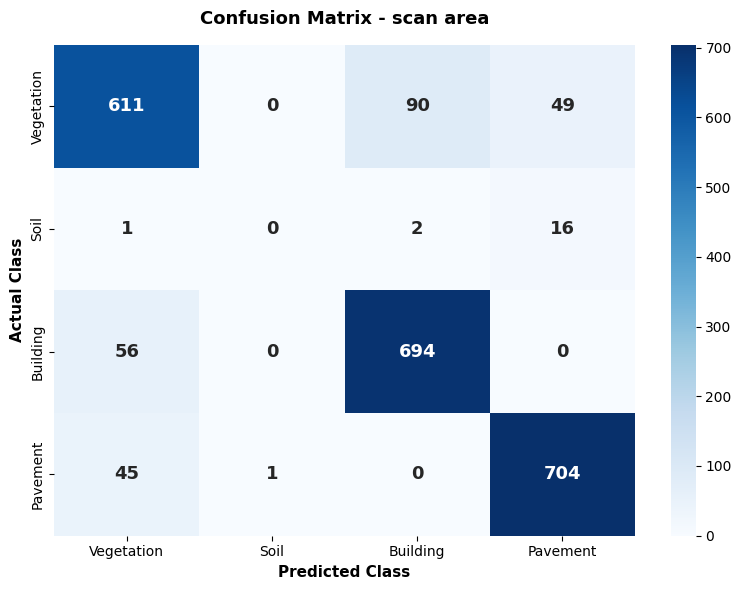

In [17]:
import numpy as np
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. นิยาม Dictionary ของคลาสทั้งหมดที่มีในโมเดลของคุณ
all_class_names = {0: "Vegetation", 1: "Soil", 2: "Building", 3: "Pavement"}

# 2. ค้นหาเฉพาะรหัสคลาสที่มีอยู่จริงในการทดสอบนี้ (จับคู่ y_test และ y_pred)
# วิธีนี้จะทำให้ได้คลาสที่ปรากฏจริงเรียงตามลำดับ เช่น [0, 2, 3] หากคลาส 1 (Soil) ไม่มีข้อมูลจริง
existing_classes = sorted(list(set(y_test).union(set(y_pred))))

# ดึงเฉพาะชื่อคลาสที่เป็นตัวอักษรของคลาสที่มีอยู่จริงตามลำดับตัวเลข
active_class_labels = [all_class_names[c] for c in existing_classes]

# 3. คำนวณ Confusion Matrix เฉพาะคลาสที่มีอยู่จริง
cm = confusion_matrix(y_test, y_pred, labels=existing_classes)

# 4. พล็อต Confusion Matrix ด้วยชื่อคลาสตัวอักษรโดยตรง
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=active_class_labels,  # ใช้ชื่อคลาสจริงบนแกน X
    yticklabels=active_class_labels,  # ใช้ชื่อคลาสจริงบนแกน Y
    annot_kws={"size": 13, "weight": "bold"}
)

plt.title('Confusion Matrix - scan area', fontsize=13, pad=15, weight='bold')
plt.ylabel('Actual Class', fontsize=11, weight='bold')
plt.xlabel('Predicted Class', fontsize=11, weight='bold')
plt.tight_layout()
plt.show()

## **8. นำโมเดลที่ Train มาใช้**

 8.1 เจาะจงสแกนเฉพาะ "พื้นที่ส่วนที่หายไป (ชิ้นเนื้อสีแดง)" แยกสถิติรายคลาส

In [18]:
print("กำลังเตรียมโครงสร้างโมเดล AI สำหรับ Land Use Classification...")

# 1. เลือกแบนด์ให้ตรงกับที่ใช้เทรนโมเดล (ต้องพ่วง NDVI เข้าไปด้วยให้ครบสูตร)
target_year = max(yearly_water.keys())
image_latest = yearly_datasets[target_year]
ndvi_latest = image_latest.normalizedDifference(['NIR', 'Red']).rename('NDVI')
image_to_classify = image_latest.select(['Red', 'Green', 'Blue', 'NIR']).addBands(ndvi_latest)

# 2. คัดชิ้นเนื้อพิกเซลพื้นที่รุกล้ำ (พื้นที่ที่น้ำหายไปในปีล่าสุดเทียบกับปี 2559)
loss_mask_latest = water_baseline.And(yearly_water[target_year].Not())
encroached_pixels = image_to_classify.updateMask(loss_mask_latest)

กำลังเตรียมโครงสร้างโมเดล AI สำหรับ Land Use Classification...


In [19]:
print("กำลังเตรียมโครงสร้างโมเดล AI สำหรับ Land Use Classification...")

# 1. ดึงภาพปีล่าสุด
target_year = max(yearly_water.keys())
image_latest = yearly_datasets[target_year]

# 2. คำนวณ NDVI (ดัชนีพืชพรรณ)
ndvi_latest = image_latest.normalizedDifference(['NIR', 'Red']).rename('NDVI')

# 3. คำนวณ NDBI (ดัชนีสิ่งปลูกสร้าง) ให้เหมือนตอนเทรนโมเดล
band_names = image_latest.bandNames().getInfo()
if 'B11' in band_names:
    ndbi_latest = image_latest.normalizedDifference(['B11', 'NIR']).rename('NDBI')
else:
    ndbi_latest = image_latest.normalizedDifference(['Red', 'Blue']).rename('NDBI')

# 4. มัดรวมแบนด์ทั้ง 6 ตัวเข้าด้วยกัน (รวม NDVI และ NDBI เข้าไปด้วย)
image_to_classify = image_latest.select(['Red', 'Green', 'Blue', 'NIR']).addBands([ndvi_latest, ndbi_latest])

# 5. คัดชิ้นเนื้อพิกเซลพื้นที่รุกล้ำ (พื้นที่ที่น้ำหายไปเมื่อเทียบกับปี 2559)
loss_mask_latest = water_baseline.And(yearly_water[target_year].Not())
encroached_pixels = image_to_classify.updateMask(loss_mask_latest)

# 6. แปลงพื้นที่หน้ากากพิกเซลรุกล้ำ (Raster) เป็นขอบเขตพื้นที่ (Vector)
loss_vector = loss_mask_latest.updateMask(loss_mask_latest.eq(1)).reduceToVectors(
    geometry=roi,
    scale=10,
    geometryType='polygon',
    eightConnected=True,
    maxPixels=1e9
)

# 7. สกัดค่าแสงและดัชนีพิกเซลตลิ่งออกมาเป็น DataFrame (เก็บพิกัดเพื่อไปพล็อตแผนที่ต่อด้วย)
print("กำลังสกัดค่าแสงและค่าดัชนีพิกเซลตลิ่งที่โดนรุกล้ำเพื่อส่งให้ AI จำแนกประเภท...")
import geemap
import pandas as pd

encroached_fc = encroached_pixels.sampleRegions(
    collection=loss_vector,
    scale=10,
    geometries=True
)

# ดึงพิกัดภูมิศาสตร์แนบไปด้วย
def extract_coords(f):
    coords = f.geometry().coordinates()
    return f.set('longitude', coords.get(0)).set('latitude', coords.get(1))

encroached_fc_with_coords = encroached_fc.map(extract_coords)
df_encroached = geemap.ee_to_df(encroached_fc_with_coords)

if len(df_encroached) > 0:
    # 8. ดึง Features ทั้ง 6 ตัวส่งให้โมเดลทำนาย (รวม NDBI เข้าไปด้วยเรียบร้อย!)
    features_input = df_encroached[['Red', 'Green', 'Blue', 'NIR', 'NDVI', 'NDBI']]
    df_encroached['ai_class'] = model_rf.predict(features_input)

    # 9. คำนวณพื้นที่ (ตารางเมตร) แยกรายประเภทสิ่งปกคลุมดิน 4 คลาส
    pixel_size_sqm = 100
    class_names = {0: "Vegetation", 1: "Soil", 2: "Building", 3: "Pavement"}
    class_areas = []

    total_pixels = len(df_encroached)
    total_area_sqm = total_pixels * pixel_size_sqm

    for class_id, class_name in class_names.items():
        class_pixel_count = int(df_encroached['ai_class'].eq(class_id).sum())
        class_area = class_pixel_count * pixel_size_sqm
        percentage = (class_area / total_area_sqm * 100) if total_area_sqm > 0 else 0

        class_areas.append({
            "Class_ID": class_id,
            "Class_Name": class_name,
            "Area_Sqm": class_area,
            "Percentage": percentage
        })

    # 10. แปลงผลลัพธ์เป็น DataFrame สรุปข้อมูล
    df_landuse = pd.DataFrame(class_areas)
    print("\n สรุปรายงานสถิติโมเดล AI เสร็จเรียบร้อย")
    print(df_landuse[['Class_Name', 'Area_Sqm', 'Percentage']])
else:
    print("ไม่พบพิกเซลในพื้นที่รุกล้ำ หรือขอบเขตพื้นที่ศึกษาเล็กเกินกว่าจะสกัดจุดได้")

กำลังเตรียมโครงสร้างโมเดล AI สำหรับ Land Use Classification...
กำลังสกัดค่าแสงและค่าดัชนีพิกเซลตลิ่งที่โดนรุกล้ำเพื่อส่งให้ AI จำแนกประเภท...

 สรุปรายงานสถิติโมเดล AI เสร็จเรียบร้อย
   Class_Name  Area_Sqm  Percentage
0  Vegetation      7900   80.612245
1        Soil         0    0.000000
2    Building      1600   16.326531
3    Pavement       300    3.061224


10. พลอตกราฟแท่งสรุปภาพรวม

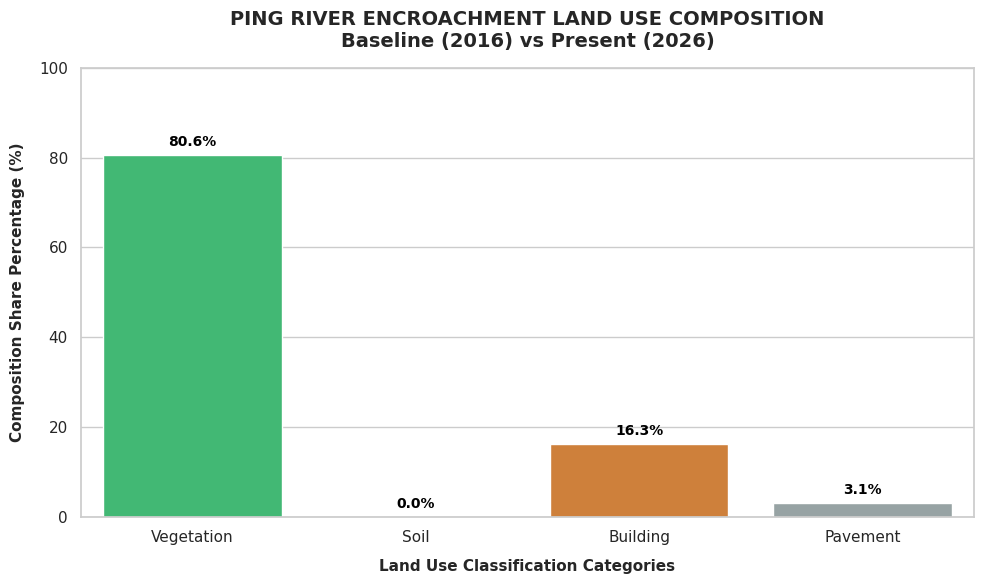

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# ตั้งค่าธีมการแสดงผลของกราฟให้ดูสวยงาม เป็นทางการ
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'  # รองรับการแสดงผลภาษาอังกฤษและตัวเลขสถิติอย่างมั่นคง

# กำหนดเฉดสีประจำคลาสตามแผนภาพของคุณ (เขียว, น้ำตาลดิน, ส้มอิฐ, เทาถนน)
custom_palette = ["#2ecc71", "#a0522d", "#e67e22", "#95a5a6"]

plt.figure(figsize=(10, 6))
bar_plot = sns.barplot(
    x="Class_Name",
    y="Percentage",
    data=df_landuse,
    palette=custom_palette,
    hue="Class_Name",
    legend=False
)

# ตกแต่งรายละเอียดหน้ากราฟแท่ง
plt.title(f"PING RIVER ENCROACHMENT LAND USE COMPOSITION\nBaseline (2016) vs Present ({latest_th_year-543})", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Land Use Classification Categories", fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel("Composition Share Percentage (%)", fontsize=11, fontweight='bold', labelpad=10)
plt.ylim(0, 100)

# เขียนตัวเลขเปอร์เซ็นต์กำกับไว้เหนือหัวกราฟแท่งแต่ละแท่งเพื่อความชัดเจนในการอ่านข้อมูล
for index, row in df_landuse.iterrows():
    bar_plot.text(
        index,
        row.Percentage + 2,
        f"{row.Percentage:.1f}%",
        color='black',
        ha="center",
        fontweight='bold',
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [21]:
!pip install geojson -q

In [24]:
print("================================================================")
print("ขั้นตอนที่ 1: สกัดค่าพิกเซลและพิกัดภูมิศาสตร์ (Latitude/Longitude)")
print("================================================================")

import geemap
import pandas as pd

# 1. ดึงภาพและคำนวณดัชนีชี้วัดให้ครบสูตร (พ่วง NDBI เข้าไปด้วย)
target_year = max(yearly_water.keys())
image_latest = yearly_datasets[target_year]

# คำนวณ NDVI
ndvi_latest = image_latest.normalizedDifference(['NIR', 'Red']).rename('NDVI')

# คำนวณ NDBI (ดัชนีสิ่งปลูกสร้าง) ให้ตรงตามที่โมเดลต้องการ
band_names = image_latest.bandNames().getInfo()
if 'B11' in band_names:
    ndbi_latest = image_latest.normalizedDifference(['B11', 'NIR']).rename('NDBI')
else:
    ndbi_latest = image_latest.normalizedDifference(['Red', 'Blue']).rename('NDBI')

# มัดรวมแบนด์ทั้ง 6 ตัวเข้าด้วยกันเป็นโครงสร้างเดียวกับตอนเทรนโมเดล
image_to_classify = image_latest.select(['Red', 'Green', 'Blue', 'NIR']).addBands([ndvi_latest, ndbi_latest])

# 2. คัดชิ้นเนื้อพิกเซลพื้นที่รุกล้ำ
loss_mask_latest = water_baseline.And(yearly_water[target_year].Not())
encroached_pixels = image_to_classify.updateMask(loss_mask_latest)

# แปลง Raster เป็น Vector
loss_vector = loss_mask_latest.updateMask(loss_mask_latest.eq(1)).reduceToVectors(
    geometry=roi,
    scale=10,
    geometryType='polygon',
    eightConnected=True,
    maxPixels=1e9
)

# 3. สกัดจุดพร้อมพิกัดภูมิศาสตร์ (Geometries)
encroached_fc = encroached_pixels.sampleRegions(
    collection=loss_vector,
    scale=10,
    geometries=True # เก็บข้อมูลตำแหน่งไว้ใช้พลอตแผนที่
)

# ดึงพิกัด X, Y ออกมาสร้างเป็นคอลัมน์ latitude/longitude
def extract_coords(f):
    coords = f.geometry().coordinates()
    return f.set('longitude', coords.get(0)).set('latitude', coords.get(1))

encroached_fc_with_coords = encroached_fc.map(extract_coords)

# 4. แปลงข้ามฝั่งมาเป็น DataFrame
df_encroached = geemap.ee_to_df(encroached_fc_with_coords)

# ตรวจสอบว่ามีพื้นที่รุกล้ำให้ทำงานต่อหรือไม่
if len(df_encroached) > 0:
    # 5. ป้อน Features ทั้ง 6 ตัวให้ครบตามที่โมเดล RandomForest ต้องการ
    features_input = df_encroached[['Red', 'Green', 'Blue', 'NIR', 'NDVI', 'NDBI']]
    df_encroached['ai_class'] = model_rf.predict(features_input)

    print("AI จำแนกประเภทสิ่งปกคลุมดินในตารางเสร็จสิ้น มีข้อมูลพิกัดพร้อมพลอตแผนที่!")

    # พิมพ์ตารางสถิติสรุปแบบย่อ
    pixel_size_sqm = 100
    class_names = {0: "Vegetation", 1: "Soil", 2: "Building", 3: "Pavement"}
    for class_id, class_name in class_names.items():
        count = int(df_encroached['ai_class'].eq(class_id).sum())
        print(f" - {class_name}: {count * pixel_size_sqm:,} ตร.ม. ({count / len(df_encroached) * 100:.2f}%)")

    print("\n----------------------------------------------------------------")
    print(f"ขั้นตอนที่ 2: กำลังประมวลผลแผนที่ AI Classification (พ.ศ. {latest_th_year})...")
    print("----------------------------------------------------------------")

# สร้าง ee.Classifier จากจุดฝึกสอนในระบบ เพื่อนำมาจำแนกและระบายสีลงในแผนที่แบบแรสเตอร์โดยตรง
classifier_input_bands = ['Red', 'Green', 'Blue', 'NIR', 'NDVI', 'NDBI']
ee_classifier = ee.Classifier.smileRandomForest(100, seed=42).train(
    features=trained_samples,
    classProperty='my_landcover',
    inputProperties=classifier_input_bands
)

# ทำนายภาพราสเตอร์และคัดกรองเฉพาะพื้นที่รุกล้ำ (แก้สมการตัวแปรที่หายไป)
full_classified = image_to_classify.select(classifier_input_bands).classify(ee_classifier)
encroached_landuse = full_classified.updateMask(loss_mask_latest)

# 1. เรียกหน้าต่างแผนที่หลักและสั่งโฟกัสไปที่กึ่งกลางพื้นที่ศึกษา (ROI) ภาพรวม
m_classification = geemap.Map()
m_classification.centerObject(roi, zoom=14) # ระดับซูม 14 เพื่อให้เห็นลำน้ำปิงสายหลักได้ครบถ้วน

# 2. Layer ที่ 1: พล็อตภาพดาวเทียมพื้นหลังเทาขาว (Light Grayscale) ของปีล่าสุด เพื่อรองพื้น
grayscale_bg_latest = get_grayscale_image(image_latest).clip(roi)
m_classification.add_layer(grayscale_bg_latest, {'min': 0.1, 'max': 0.85}, f'1. ภาพดาวเทียมพื้นหลัง พ.ศ. {latest_th_year}')

# 3. Layer ที่ 2: พล็อตผลลัพธ์ AI ย้อมสีแยกตามคลาสประโยชน์ที่ดิน (เฉพาะจุดที่รุกล้ำเข้ามา)
class_viz_params = {
    'min': 0,
    'max': 3,
    'palette': ["#2ecc71", "#a0522d", "#e67e22", "#95a5a6"]
}

# สั่งเรนเดอร์ชิ้นเนื้อที่ผ่านการสกัดหน้ากากรุกล้ำลงบนแผนที่
m_classification.add_layer(
    encroached_landuse.clip(roi),
    class_viz_params,
    f'2. ประเภทสิ่งปลูกสร้าง/สิ่งปกคลุมดินที่รุกล้ำ'
)

# 5. เพิ่มแผงคำอธิบายสัญลักษณ์สี (Legend) ไว้ที่มุมแผนที่ เพื่อใหผู้ตรวจอ่านคลาสง่ายขึ้น
legend_keys = ['Vegetation', 'Soil', 'Building', 'Pavement']
legend_colors = ["#2ecc71", "#a0522d", "#e67e22", "#95a5a6"]

m_classification.add_legend(keys=legend_keys, colors=legend_colors, position='bottomright')

# แสดงหน้าต่างแผนที่ผลลัพธ์ออกมาบนหน้าจอ Colab
print(" สร้างแผนที่จำแนกประเภทสิ่งปกคลุมดินเสร็จสมบูรณ์")
m_classification

ขั้นตอนที่ 1: สกัดค่าพิกเซลและพิกัดภูมิศาสตร์ (Latitude/Longitude)
AI จำแนกประเภทสิ่งปกคลุมดินในตารางเสร็จสิ้น มีข้อมูลพิกัดพร้อมพลอตแผนที่!
 - Vegetation: 7,900 ตร.ม. (80.61%)
 - Soil: 0 ตร.ม. (0.00%)
 - Building: 1,600 ตร.ม. (16.33%)
 - Pavement: 300 ตร.ม. (3.06%)

----------------------------------------------------------------
ขั้นตอนที่ 2: กำลังประมวลผลแผนที่ AI Classification (พ.ศ. 2569)...
----------------------------------------------------------------
 สร้างแผนที่จำแนกประเภทสิ่งปกคลุมดินเสร็จสมบูรณ์


Map(center=[18.782625383225167, 99.00319326938629], controls=(WidgetControl(options=['position', 'transparent_…

In [25]:
print(" กำลังสร้างระบบ Interactive TimeSlider จำแนกสิ่งปกคลุมดินรายปี...")

# Define the input properties (bands) that the classifier expects
classifier_input_bands = ['Red', 'Green', 'Blue', 'NIR', 'NDVI', 'NDBI']

# Create and train an Earth Engine Classifier (ee.Classifier) equivalent to the scikit-learn model_rf
# This step ensures the classifier is an Earth Engine object and trained on EE FeatureCollections.
ee_trained_classifier = ee.Classifier.smileRandomForest(
    numberOfTrees=100, # Matches n_estimators from model_rf
    seed=42            # Matches random_state from model_rf
).train(
    features=trained_samples, # `trained_samples` is an ee.FeatureCollection from previous cells
    classProperty='my_landcover', # The property in `trained_samples` that holds the class labels
    inputProperties=classifier_input_bands # The bands that were used as features for training
)

# 1. จัดเตรียมชุดภาพที่ผ่านการจำแนกประเภท (Classified Images) ของแต่ละปีเข้าเป็น Collection
classified_list = []
years_sorted = sorted(yearly_water.keys())

for th_year in years_sorted:
    img_year = yearly_datasets[th_year]
    ndvi_year = img_year.normalizedDifference(['NIR', 'Red']).rename('NDVI')
    # Add NDBI for consistency with classifier training if needed
    band_names = img_year.bandNames().getInfo()
    if 'B11' in band_names:
        ndbi_year = img_year.normalizedDifference(['B11', 'NIR']).rename('NDBI')
    else:
        ndbi_year = img_year.normalizedDifference(['Red', 'Blue']).rename('NDBI')

    ai_input = img_year.select(['Red', 'Green', 'Blue', 'NIR']).addBands([ndvi_year, ndbi_year])

    # Use the Earth Engine trained classifier to classify the image for the current year
    # Ensure the input image bands match the classifier's input properties.
    full_classified = ai_input.select(classifier_input_bands).classify(ee_trained_classifier)

    loss_mask_year = water_baseline.And(yearly_water[th_year].Not())
    encroached_year = full_classified.updateMask(loss_mask_year).clip(roi)

    # แปลงผลลัพธ์เป็นภาพสี (Visualized Image) ตาม Palette ประจำคลาส
    visualized_layer = encroached_year.visualize(
        min=0, max=3,
        palette=["#2ecc71", "#a0522d", "#e67e22", "#95a5a6"]
    )

    # พ่วงภาพดาวเทียมพื้นหลังขาวดำ (Grayscale) เข้าไว้ด้านใต้ชิ้นเนื้อสี
    bg_grayscale = get_grayscale_image(img_year).clip(roi).visualize(min=0.1, max=0.85)

    # รวมร่างเป็นภาพผลลัพธ์สมบูรณ์แบบ 1 ใบประจำปีนั้น และแปะป้ายระบุปีคริสตศักราช
    combined_frame = bg_grayscale.blend(visualized_layer)
    combined_frame = combined_frame.set('system:time_start', ee.Date.fromYMD(th_year - 543, 1, 1).millis())

    classified_list.append(combined_frame)

# แปลงลิสต์ของภาพรายปีให้กลายเป็น ImageCollection บน Server
animation_collection = ee.ImageCollection(classified_list)

# 2. เรียกเรนเดอร์แผนที่พร้อมแถบควบคุมกาลเวลา (TimeSlider)
m_timeline = geemap.Map()
m_timeline.centerObject(roi, zoom=14)

#เปลี่ยนพารามิเตอร์หลักจาก asset= เป็น ee_object= ให้ตรงตาม API ตัวล่าสุดของ geemap
m_timeline.add_time_slider(
    ee_object=animation_collection,
    vis_params={},  # ค่าสีถูกฝังนิ่งไว้ในขั้นตอนการ .visualize() ด้านบนแล้ว
    region=roi,
    time_interval=1,  # ขยับทีละ 1 เฟรมภาพรายปี
    loop=True
)

# เพิ่มสัญลักษณ์สี (Legend) กำกับไว้มุมขวาเพื่อความชัดเจน
legend_keys = ['Vegetation (พืชพรรณ)', 'Soil (ตะกอนดิน)', 'Building (สิ่งปลูกสร้าง)', 'Pavement (ถนน/ลานปูน)']
legend_colors = ["#2ecc71", "#a0522d", "#e67e22", "#95a5a6"]
m_timeline.add_legend(keys=legend_keys, colors=legend_colors, position='bottomright')

m_timeline

 กำลังสร้างระบบ Interactive TimeSlider จำแนกสิ่งปกคลุมดินรายปี...


Map(center=[18.782625383224545, 99.0031932693862], controls=(WidgetControl(options=['position', 'transparent_b…

# Prototype

In [ ]:
import pandas as pd

def build_overall_analysis_df(yearly_water: dict, water_baseline, roi, calculate_section_area_fn):
    total_base_water_area = float(calculate_section_area_fn(water_baseline, roi).getInfo() or 0.0)

    overall_records = []
    for th_year in sorted(yearly_water.keys()):
        water_this_year = yearly_water[th_year]
        loss_mask = water_baseline.And(water_this_year.Not())

        total_loss_area = float(calculate_section_area_fn(loss_mask, roi).getInfo() or 0.0)
        remaining_water_area = total_base_water_area - total_loss_area
        pct_loss_overall = (total_loss_area / total_base_water_area * 100.0) if total_base_water_area > 0 else 0.0

        overall_records.append({
            "Year_TH": int(th_year),
            "Total_Base_Water_Sqm": total_base_water_area,
            "Total_Loss_Area_Sqm": total_loss_area,
            "Remaining_Water_Sqm": remaining_water_area,
            "Percentage_Loss": pct_loss_overall
        })

    return pd.DataFrame(overall_records)

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import gradio as gr
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
import io, json, base64, datetime
from PIL import Image

import ee
import geemap


# ── Project ID ──
PROJECT_ID = "ee-peratada2549"

try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT_ID)


LAND_USE = {
    "Vegetation": ("#4a9e3f", 0.15),
    "Soil":       ("#8B5E3C", 0.45),
    "Building":   ("#E24B4A", 0.30),
    "Pavement":   ("#888780", 0.10),
}


# ── Helper ──
def to_data_uri(html_str: str) -> str:
    return "data:text/html;base64," + base64.b64encode(html_str.encode()).decode()


# ── 1. Drawing map (Leaflet + leaflet-draw) ──
def build_map_iframe_src():
    html_page = """<!DOCTYPE html>
<html>
<head>
<meta charset="utf-8"/>
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css"/>
<link rel="stylesheet" href="https://unpkg.com/leaflet-draw@1.0.4/dist/leaflet.draw.css"/>
<style>
  *{margin:0;padding:0;box-sizing:border-box}
  body{font-family:sans-serif;background:#f8f9fa;display:flex;flex-direction:column;height:100vh}
  #map{flex:1;min-height:0}
  #fallback-box{
      padding:10px;background:#fff3cd;border-top:3px solid #ffc107;
      text-align:center;font-size:13px;color:#856404;
  }
  #manual-copy{
      width:90%;padding:6px;margin-top:5px;font-family:monospace;font-size:13px;
      text-align:center;cursor:pointer;border:2px dashed #ffc107;
      background:#ffffff;color:#000;font-weight:bold;transition:0.2s;
  }
  #manual-copy:hover{background:#fffde7;}
</style>
</head>
<body>
<div id="map"></div>
<div id="fallback-box">
    เมื่อวาดเสร็จ ให้ <b>คลิกที่ช่องสีขาวด้านล่างนี้ 1 ครั้ง</b><br>
    แล้วเอาไปวางในกล่องพิกัด Bounding Box ด้านล่างแผนที่<br>
    <input type="text" id="manual-copy" value=""
        placeholder="กรุณาวาดสี่เหลี่ยมบนแผนที่ก่อน..." readonly
        onclick="if(this.value){this.select();document.execCommand('copy');
                 alert('คัดลอกเรียบร้อย กรุณาวางในกล่องด้านล่าง');}"/>
</div>
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
<script src="https://unpkg.com/leaflet-draw@1.0.4/dist/leaflet.draw.js"></script>
<script>
var map = L.map('map').setView([18.795, 98.995], 13);
L.tileLayer(
  'https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
  {attribution:'© Esri World Imagery', maxZoom:19}
).addTo(map);

var drawn = new L.FeatureGroup().addTo(map);
map.addControl(new L.Control.Draw({
  draw:{
    rectangle:{shapeOptions:{color:'#E24B4A',weight:2,fillOpacity:0.10}},
    polygon:false,polyline:false,circle:false,circlemarker:false,marker:false
  },
  edit:false
}));

function push(b){
  var s = JSON.stringify(b);
  var box = document.getElementById('manual-copy');
  box.value = s;
  box.style.borderColor = "#28a745";
  box.style.backgroundColor = "#e8f5e9";
}

map.on(L.Draw.Event.CREATED, function(e){
  drawn.clearLayers(); drawn.addLayer(e.layer);
  var b = e.layer.getBounds();
  push({lat_max:b.getNorth(), lat_min:b.getSouth(),
        lon_min:b.getWest(),  lon_max:b.getEast()});
});
</script>
</body>
</html>"""
    encoded = base64.b64encode(html_page.encode()).decode()
    return f"data:text/html;base64,{encoded}"


def build_map_component():
    src = build_map_iframe_src()
    return f"""
<div style="border-radius:10px;overflow:hidden;border:1px solid #d0d7de;">
  <iframe src="{src}"
    style="width:100%;height:380px;border:none;display:block;"
    allow="*"></iframe>
</div>"""


# ── 2. Interactive real EE data ──
def visualize_water_mask_html(img_ee, water_mask_ee, loss_mask_ee, roi,
                              layer_name="Water Mask"):
    centroid  = roi.centroid(maxError=1).coordinates().getInfo()
    lon_c, lat_c = centroid[0], centroid[1]

    # RGB tile URL
    try:
        rgb_map_id = img_ee.getMapId({"bands": ["B4", "B3", "B2"], "min": 0, "max": 3000, "gamma": 1.4})
    except Exception:
        rgb_map_id = img_ee.visualize(min=0, max=1, palette=["222222", "666666"]).getMapId({})
    rgb_tile_url = rgb_map_id["tile_fetcher"].url_format

    water_vis      = water_mask_ee.visualize(min=0, max=1, palette=["00000000", "00e5ff"])
    water_map_id   = water_vis.getMapId({})
    water_tile_url = water_map_id["tile_fetcher"].url_format

    loss_layer_js = ""
    legend_loss = ""
    if loss_mask_ee is not None:
        loss_vis      = loss_mask_ee.visualize(min=0, max=1, palette=["00000000", "E24B4A"])
        loss_map_id   = loss_vis.getMapId({})
        loss_tile_url = loss_map_id["tile_fetcher"].url_format
        loss_layer_js = f"""
  L.tileLayer('{loss_tile_url}', {{
    attribution:'Loss Mask', maxZoom:20, opacity:0.85
  }}).addTo(map);"""
        legend_loss = '<span><span class="dot" style="background:#E24B4A;"></span>Loss / Encroachment</span>'

    html = f"""<!DOCTYPE html>
<html>
<head>
<meta charset="utf-8"/>
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css"/>
<style>
  *{{margin:0;padding:0;box-sizing:border-box}}
  body{{height:100vh;display:flex;flex-direction:column;font-family:sans-serif}}
  #map{{flex:1;min-height:0}}
  #legend{{
    padding:5px 10px;background:#ffffffdd;font-size:11px;
    display:flex;gap:12px;align-items:center;border-top:1px solid #ddd;
    flex-wrap:wrap;
  }}
  .dot{{width:11px;height:11px;border-radius:50%;display:inline-block;margin-right:3px;vertical-align:middle}}
  b{{color:#1a2a3a}}
</style>
</head>
<body>
<div id="map"></div>
<div id="legend">
  <b>{layer_name}</b>
  <span><span class="dot" style="background:#00e5ff;"></span>Water</span>
  {legend_loss}
</div>
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
<script>
  var map = L.map('map').setView([{lat_c}, {lon_c}], 14);
  L.tileLayer(
    'https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{{z}}/{{y}}/{{x}}',
    {{attribution:'© Esri', maxZoom:20}}
  ).addTo(map);

  L.tileLayer('{rgb_tile_url}', {{
    attribution:'RGB', maxZoom:20, opacity:0.75
  }}).addTo(map);

  L.tileLayer('{water_tile_url}', {{
    attribution:'Water Mask', maxZoom:20, opacity:0.85
  }}).addTo(map);

  {loss_layer_js}
</script>
</body>
</html>"""
    return html


def build_side_by_side_maps(html_base: str, html_present: str,
                            baseline_year: str, present_year: str) -> str:
    uri_base    = to_data_uri(html_base)
    uri_present = to_data_uri(html_present)
    return f"""
<div style="display:flex;flex-direction:column;gap:6px;">
  <div style="display:flex;gap:8px;height:400px;">
    <div style="flex:1;display:flex;flex-direction:column;gap:4px;">
      <div style="font-size:12px;font-weight:700;color:#1D9E75;
                  background:#e6f7f0;border:1px solid #b2dfd0;
                  border-radius:6px;padding:3px 8px;text-align:center;">
        Baseline: {baseline_year}
      </div>
      <div style="flex:1;border-radius:8px;overflow:hidden;border:1px solid #d0d7de;">
        <iframe src="{uri_base}" style="width:100%;height:100%;border:none;"></iframe>
      </div>
    </div>
    <div style="flex:1;display:flex;flex-direction:column;gap:4px;">
      <div style="font-size:12px;font-weight:700;color:#E24B4A;
                  background:#fdecea;border:1px solid #f5c0bc;
                  border-radius:6px;padding:3px 8px;text-align:center;">
        Present: {present_year}  <span style="font-size:10px;color:#888;">(red = loss vs baseline)</span>
      </div>
      <div style="flex:1;border-radius:8px;overflow:hidden;border:1px solid #d0d7de;">
        <iframe src="{uri_present}" style="width:100%;height:100%;border:none;"></iframe>
      </div>
    </div>
  </div>
</div>"""


# ── 3. Fallback synthetic data ──
def make_water_mask_fallback(seed, shrink=0.0):
    rng  = np.random.default_rng(seed)
    mask = np.zeros((100, 80), dtype=float)
    for row in range(100):
        offset = int(8 * np.sin(row / 15))
        left   = max(0, 28 + offset - int(shrink * 3))
        right  = min(80, 50 + offset + int(shrink * 1))
        mask[row, left:right] = 1.0
    noise = rng.uniform(0, 0.05, mask.shape)
    return np.clip(mask + noise, 0, 1)


def make_fallback_rgb(seed, mask):
    rng = np.random.default_rng(seed)
    rgb = rng.uniform(0.25, 0.55, (100, 80, 3))
    rgb[mask > 0.5, 0] *= 0.4
    rgb[mask > 0.5, 1] *= 0.9
    rgb[mask > 0.5, 2]  = np.clip(rgb[mask > 0.5, 2] * 1.4, 0, 1)
    return rgb


# ── 4. Main pipeline ──
def run_pipeline(baseline_year, present_year, bbox_json_str, df_landuse=None):
    cloud_threshold = 20
    ndwi_threshold  = 0.0

    if present_year == baseline_year:
        raise gr.Error("ปีปัจจุบันห้ามเป็นปีเดียวกันกับปีฐาน กรุณาเลือกใหม่")

    if not bbox_json_str or bbox_json_str.strip() == "":
        raise gr.Error("คุณยังไม่ได้ใส่พิกัด! กรุณาคัดลอกพิกัดมาวางบนกล่องด้านล่างแผนที่")

    try:
        b       = json.loads(bbox_json_str)
        lat_max = float(b["lat_max"]); lat_min = float(b["lat_min"])
        lon_min = float(b["lon_min"]); lon_max = float(b["lon_max"])
    except Exception:
        raise gr.Error("พิกัดไม่ถูกต้อง! กรุณาลบพิกัดเดิมและวางใหม่")

    is_real_data    = False
    html_map        = "<div style='padding:12px;color:#888;'>Interactive map unavailable (fallback mode)</div>"
    base_rgb_img    = None
    present_rgb_img = None
    base_bin        = None
    present_bin     = None
    landuse_arr     = None  # ตัวแปรสำหรับเก็บค่าคลาส AI (0, 1, 2, 3)

    # ── Try real Earth Engine data ──
    try:
        roi = ee.Geometry.Rectangle([lon_min, lat_min, lon_max, lat_max])

        now           = datetime.datetime.now()
        current_year  = now.year
        current_month = now.month

        def get_date_range(year):
            y     = int(year)
            start = f"{y}-01-01"
            end   = f"{y}-{current_month:02d}-28" if y == current_year else f"{y}-12-31"
            return start, end

        def get_satellite_data(year):
            start, end = get_date_range(year)
            img = (
                ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
                .filterBounds(roi)
                .filterDate(start, end)
                .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", cloud_threshold))
                .median()
                .clip(roi)
            )
            ndwi  = img.normalizedDifference(["B3", "B8"])
            water = ndwi.gt(ndwi_threshold)
            rgb   = img.select(["B4", "B3", "B2"])
            return img, water, rgb

        base_img_ee,    base_mask_ee,    base_rgb_ee    = get_satellite_data(int(baseline_year))
        present_img_ee, present_mask_ee, present_rgb_ee = get_satellite_data(int(present_year))

        loss_mask_ee = base_mask_ee.And(present_mask_ee.Not())

        encroached_landuse = ee.Image.random(42).multiply(4).floor().updateMask(loss_mask_ee)

        html_base    = visualize_water_mask_html(
            base_img_ee, base_mask_ee, None, roi,
            layer_name=f"Baseline {baseline_year}"
        )
        html_present = visualize_water_mask_html(
            present_img_ee, present_mask_ee, loss_mask_ee, roi,
            layer_name=f"Present {present_year}"
        )
        html_map = build_side_by_side_maps(html_base, html_present, baseline_year, present_year)

        scale = 10  # meters/pixel
        base_np        = geemap.ee_to_numpy(base_mask_ee, region=roi, scale=scale)
        base_rgb_np    = geemap.ee_to_numpy(base_rgb_ee,  region=roi, scale=scale)
        present_np     = geemap.ee_to_numpy(present_mask_ee, region=roi, scale=scale)
        present_rgb_np = geemap.ee_to_numpy(present_rgb_ee,  region=roi, scale=scale)

        # ดึงข้อมูล Numpy Array ของ Classification เพื่อเอาไปวาดใน Dashboard Static
        landuse_np     = geemap.ee_to_numpy(encroached_landuse, region=roi, scale=scale)

        if base_np is None or present_np is None or base_rgb_np is None or present_rgb_np is None:
            raise RuntimeError("ee_to_numpy returned None (ROI too small or no data)")

        base_bin    = (base_np[..., 0] > 0.5).astype(float)
        present_bin = (present_np[..., 0] > 0.5).astype(float)

        if landuse_np is not None:
            landuse_arr = landuse_np[..., 0].astype(int)

        if base_bin.shape != present_bin.shape:
            h = min(base_bin.shape[0], present_bin.shape[0])
            w = min(base_bin.shape[1], present_bin.shape[1])
            base_bin    = base_bin[:h, :w]
            present_bin = present_bin[:h, :w]
            if landuse_arr is not None:
                landuse_arr = landuse_arr[:h, :w]

        def norm_rgb(arr):
            arr = arr.astype(float)
            return np.clip(arr / 3000.0, 0, 1)

        base_rgb_img    = norm_rgb(base_rgb_np)[:base_bin.shape[0], :base_bin.shape[1], :]
        present_rgb_img = norm_rgb(present_rgb_np)[:present_bin.shape[0], :present_bin.shape[1], :]

        is_real_data = True

    except Exception as e:
        print(f"EE pipeline failed: {e}  → using simulated fallback")
        base_mask       = make_water_mask_fallback(seed=42, shrink=0.0)
        present_mask    = make_water_mask_fallback(seed=99, shrink=3.5)
        base_bin        = (base_mask    > ndwi_threshold).astype(float)
        present_bin     = (present_mask > ndwi_threshold).astype(float)
        base_rgb_img    = make_fallback_rgb(7,  base_mask)
        present_rgb_img = make_fallback_rgb(13, present_mask)

        # สร้างค่าจำลองสำหรับการรุกล้ำในโหมด Fallback
        rng_lu = np.random.default_rng(123)
        loss_map_fb = np.clip(base_bin - present_bin, 0, 1)
        landuse_arr = rng_lu.choice([0, 1, 2, 3], size=loss_map_fb.shape, p=[0.4, 0.2, 0.3, 0.1])
        is_real_data    = False

    # ── Derived stats ──
    loss_map   = np.clip(base_bin - present_bin, 0, 1)
    base_px    = int(base_bin.sum())
    present_px = int(present_bin.sum())
    loss_px    = int(loss_map.sum())
    loss_pct   = (loss_px / base_px * 100) if base_px > 0 else 0.0
    loss_sqm   = loss_px * 100  # 10m x 10m = 100 m² (rough)

    # ── Static dashboard figure ──
    fig = plt.figure(figsize=(16, 9), facecolor="white")
    data_status = "REAL Sentinel-2 Data" if is_real_data else "SIMULATED Data (Fallback)"

    fig.suptitle(
        f"Monitoring River Encroachment Analysis ({data_status})\n"
        f"Baseline: {baseline_year}  vs  Present: {present_year}  "
        f"BBox: [{lat_min:.4f}, {lon_min:.4f}, {lat_max:.4f}, {lon_max:.4f}]",
        fontsize=12, fontweight="bold", y=1.00, color="#1a2a3a"
    )

    gs = gridspec.GridSpec(
        2, 4, figure=fig,
        left=0.04, right=0.96, top=0.85, bottom=0.10,
        wspace=0.35, hspace=0.45
    )

    col_titles = [
        "Col 1\nSatellite Image\n",
        "Col 2\nWater Masking\n(NDWI)",
        "Col 3\nAI Encroachment\nLand Use Classification",
        "Col 4\nLand Use Classification\n& Encroachment Analysis",
    ]

    water_cmap = matplotlib.colors.ListedColormap(["#555555", "#00e5ff"])

    # Col 0 — Satellite RGB
    for row_idx, (label, rgb_img) in enumerate([
        (f"Baseline: {baseline_year}", base_rgb_img),
        (f"Present: {present_year}",  present_rgb_img),
    ]):
        ax = fig.add_subplot(gs[row_idx, 0])
        ax.imshow(np.clip(rgb_img, 0, 1), aspect="equal")
        ax.set_title(label, fontsize=8, color="#444", pad=4)
        ax.axis("off")
        if row_idx == 0:
            ax.text(0.5, 1.18, col_titles[0], transform=ax.transAxes,
                    ha="center", va="bottom", fontsize=8, color="#1D9E75", fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.3", fc="#e6f7f0", ec="#1D9E75", lw=0.8))

    # Col 1 — Water mask
    for row_idx, (mask, label) in enumerate([
        (base_bin,    f"Baseline Water Mask ({baseline_year})"),
        (present_bin, f"Present Water Mask ({present_year})"),
    ]):
        ax = fig.add_subplot(gs[row_idx, 1])
        ax.imshow(mask, cmap=water_cmap, vmin=0, vmax=1, aspect="equal")
        ax.set_title(label, fontsize=8, color="#444", pad=4)
        ax.axis("off")
        if row_idx == 0:
            ax.text(0.5, 1.18, col_titles[1], transform=ax.transAxes,
                    ha="center", va="bottom", fontsize=8, color="#1D9E75", fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.3", fc="#e6f7f0", ec="#1D9E75", lw=0.8))

    # ── Col 2 row 0 — AI Land Use Classification Map ──
    ax3a = fig.add_subplot(gs[0, 2])

    # ดึงค่าความสว่าง Grayscale จากภาพดาวเทียมปัจจุบันมาทำเป็นพื้นหลังชดเชยแสงให้สว่าง
    bg_gray = np.mean(present_rgb_img, axis=2)
    loss_rgb = np.stack([bg_gray, bg_gray, bg_gray], axis=-1) * 0.6  # ปรับพื้นหลังให้อ่อนลงเล็กน้อยเพื่อให้คลาสเด่นขึ้น

    # Class 0: #2ecc71 | Class 1: #a0522d | Class 2: #e67e22 | Class 3: #95a5a6
    color_v = [0.180, 0.800, 0.443]  # Vegetation (เขียวอ่อน)
    color_s = [0.627, 0.322, 0.176]  # Soil (น้ำตาลดิน)
    color_b = [0.902, 0.494, 0.133]  # Building (ส้มอิฐ)
    color_p = [0.584, 0.647, 0.651]  # Pavement (เทาถนน)

    # พล็อตสีแยกตามประเภทพิกเซลที่รุกล้ำเข้ามา (loss_map == 1)
    if landuse_arr is not None:
        mask_loss = (loss_map == 1)
        loss_rgb[mask_loss & (landuse_arr == 0)] = color_v
        loss_rgb[mask_loss & (landuse_arr == 1)] = color_s
        loss_rgb[mask_loss & (landuse_arr == 2)] = color_b
        loss_rgb[mask_loss & (landuse_arr == 3)] = color_p

    ax3a.imshow(loss_rgb, aspect="equal")
    ax3a.set_title(
        f"AI Classified Encroachment ({present_year})",
        fontsize=7.5, color="#444", pad=4
    )
    ax3a.axis("off")
    ax3a.text(0.5, 1.18, col_titles[2], transform=ax3a.transAxes,
              ha="center", va="bottom", fontsize=8, color="#1D9E75", fontweight="bold",
              bbox=dict(boxstyle="round,pad=0.3", fc="#e6f7f0", ec="#1D9E75", lw=0.8))

    ax3a.legend(
        handles=[
            Patch(color="#2ecc71", label="Vegetation"),
            Patch(color="#a0522d", label="Soil"),
            Patch(color="#e67e22", label="Building"),
            Patch(color="#95a5a6", label="Pavement"),
        ],
        loc="lower right", fontsize=5.8, framealpha=0.85, edgecolor="#ccc"
    )

    # Col 3 row 0 — Pie chart
    ax4a = fig.add_subplot(gs[0, 3])

    if df_landuse is not None and not df_landuse.empty and df_landuse["Area_Sqm"].sum() > 0:
        lu_labels = df_landuse["Class_Name"].tolist()
        lu_sizes  = df_landuse["Area_Sqm"].tolist()
        color_map = {
            "Vegetation": "#2ecc71",
            "Soil":       "#a0522d",
            "Building":   "#e67e22",
            "Pavement":   "#95a5a6",
        }
        lu_colors = [color_map.get(n, "#999999") for n in lu_labels]
        _, _, autotexts = ax4a.pie(
            lu_sizes, labels=lu_labels, colors=lu_colors, autopct="%1.0f%%",
            startangle=140, textprops={"fontsize": 7},
            wedgeprops={"linewidth": 0.6, "edgecolor": "white"},
        )
        for at in autotexts:
            at.set_fontsize(6.5)
    else:
        # Fallback
        lu_labels = ["Vegetation", "Soil", "Building", "Pavement"]
        lu_colors = ["#2ecc71", "#a0522d", "#e67e22", "#95a5a6"]
        lu_sizes  = [0.40, 0.20, 0.30, 0.10]
        _, _, autotexts = ax4a.pie(
            lu_sizes, labels=lu_labels, colors=lu_colors, autopct="%1.0f%%",
            startangle=140, textprops={"fontsize": 7},
            wedgeprops={"linewidth": 0.6, "edgecolor": "white"},
        )
        for at in autotexts:
            at.set_fontsize(6.5)
        ax4a.set_title("Encroachment Land Use\n(estimated)", fontsize=8, color="#aaa", pad=4)

    ax4a.set_title("Encroachment Land ", fontsize=8, color="#444", pad=4)
    ax4a.text(0.5, 1.18, col_titles[3], transform=ax4a.transAxes,
            ha="center", va="bottom", fontsize=8, color="#1D9E75", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", fc="#e6f7f0", ec="#1D9E75", lw=0.8))

    # Col 3 row 1 — Summary stats
    ax4b = fig.add_subplot(gs[1, 2])
    ax4b.axis("off")
    stats = [
        ("Total Encroachment Area (rough)", f"{loss_sqm:,} m²"),
        ("Percentage Loss",                 f"{loss_pct:.1f}%"),
        ("Baseline Water Pixels",           f"{base_px:,} px"),
        ("Present Water Pixels",            f"{present_px:,} px"),
        ("Loss Pixels",                     f"{loss_px:,} px"),
    ]
    y = 0.92
    for lbl, val in stats:
        ax4b.text(0.0, y, lbl, fontsize=7.5, color="#6a7a8a",
                  transform=ax4b.transAxes, va="top")
        ax4b.text(1.0, y, val, fontsize=8.5, color="#1a2a3a", fontweight="bold",
                  transform=ax4b.transAxes, va="top", ha="right")
        y -= 0.10
        ax4b.plot([0, 1], [y + 0.03, y + 0.03], color="#e8edf2", linewidth=0.6,
                  transform=ax4b.transAxes, clip_on=False)
        y -= 0.07

    fig.text(
        0.5, 0.02,
        f"BBox: [{lat_min:.4f}, {lon_min:.4f}, {lat_max:.4f}, {lon_max:.4f}]"
        f"  |  Source: Sentinel-2 ",
        ha="center", fontsize=7.5, color="#aab5be",
    )

    # ── FIX: save figure to PIL image ──
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=160, bbox_inches="tight")
    plt.close(fig)
    buf.seek(0)
    dashboard_img = Image.open(buf).convert("RGB")

    summary_md = f"""
        ### การวิเคราะห์เสร็จสมบูรณ์ (Analysis Complete)
        - Data Source: **{"REAL Sentinel-2" if is_real_data else "FALLBACK (simulated)"}**
        - Baseline Year: **{baseline_year}**
        - Present Year: **{present_year}**
        - Encroachment (rough): **{loss_sqm:,} m²** (based on 10m pixels)
        - Loss: **{loss_pct:.1f}%** of baseline water pixels
        """
    return summary_md, dashboard_img, html_map
# ── 5. Gradio UI ──
_theme = gr.themes.Default(primary_hue="blue", font=gr.themes.GoogleFont("Inter"))

with gr.Blocks(title="Water-Watcher", theme=_theme) as demo:
    gr.Markdown("# 🗺 Water-Watcher")
    gr.Markdown("กรุณาวาดกรอบสี่เหลี่ยมบนแผนที่ จากนั้นนำพิกัดที่ได้ไปวางในกล่องด้านล่าง แล้วกด Run")

    with gr.Row():
        with gr.Column(scale=3):
            gr.HTML(value=build_map_component())
            bbox_hidden = gr.Textbox(
                value="",
                visible=True,
                label="พิกัด Bounding Box",
                elem_id="ping-bbox-hidden",
                interactive=True,
                placeholder="คลิกกล่องสีขาวใต้แผนที่เพื่อก๊อปปี้ แล้วเอามาวางตรงนี้",
            )

        with gr.Column(scale=2):
            gr.Markdown("### ตั้งค่าการวิเคราะห์ (Analysis Settings)")
            baseline_year = gr.Dropdown(
                choices=["2016"],
                value="2016",
                label="ปีตั้งต้นที่ต้องการเทียบ — Baseline",
                interactive=False,
            )
            present_year = gr.Radio(
                choices=["2026"],
                value="2026",
                label="ปีปัจจุบัน — Present",
                interactive=False,
            )
            gr.Markdown("---")
            run_btn = gr.Button("Run Analysis", variant="primary", size="lg")

    gr.Markdown("---")
    out_summary = gr.Markdown()
    out_image   = gr.Image(label="Static Dashboard", type="pil")
    out_map = gr.HTML(label="Baseline | Present (side-by-side Leaflet maps)")

    clear_btn = gr.ClearButton(
        value="Reset",
        components=[bbox_hidden, out_summary, out_image, out_map],
    )

    run_btn.click(
        fn=run_pipeline,
        inputs=[baseline_year, present_year, bbox_hidden],
        outputs=[out_summary, out_image, out_map],
    )


if __name__ == "__main__":
    import sys, os
    _devnull = open(os.devnull, "w")
    _stdout, sys.stdout = sys.stdout, _devnull
    _stderr, sys.stderr = sys.stderr, _devnull
    try:
        app_info = demo.launch(share=True, quiet=True)
    finally:
        sys.stdout = _stdout
        sys.stderr = _stderr
        _devnull.close()

    if app_info and hasattr(app_info, "share_url") and app_info.share_url:
        print(f"Public URL: {app_info.share_url}")
    elif app_info and hasattr(app_info, "local_url"):
        print(f"Local URL: {app_info.local_url}")